# **Infer `Cellmask` and `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***

In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

## **SANDBOX FOR: Improved cell/nuclei segmentation**
<ins>Goals:</ins> Improve cell mask segmentation by implementing a machine learning approach. For comparison, the original masks_C workflow (without nuclei is included first).

Current thought process:
1. Segment nuclei manually from the inverse of a composite image (based on MCZ/ZC updates) -- this is actually very similar or exactly the same as what is done in 1.1a/b (see [NEW_infer-nuc_from-inverse-cyto.ipynb](NEW_infer-nuc_from-inverse-cyto.ipynb) notebook)
2. Input the PM staining and the nuclei segmentation into CellPose
3. POSSIBLY: add a trainable option to improve cyto3 model for iAstrocytes and iNeurons

--------------


---------------------
----------
# **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [1]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles.membrane import *
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm

%load_ext autoreload
%autoreload 2

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [2]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
data_root_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")

in_data_path = data_root_path / "example-images"

im_type = ".tiff"

out_data_path = data_root_path / "202610012_testing-outputs/images_for_figures"

vis_path = data_root_path / "20261029_SR_test-sd"

#### &#x1F3C3; **Run code; no user input required**

In [3]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

if not Path.exists(vis_path):
    Path.mkdir(vis_path)
    print(f"making {vis_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\02242026_ZS_iPSCs_SOX9NFIA1_BR02_N07_Unmixing_cmle.ome.tiff
1,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\03172026_ZS_iPSCs_SOX9NFIA1_BR03_N03_Unmixing_cmle.ome.tiff
2,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N07_Unmixing_cmle.ome.tiff
3,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
4,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
5,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\11192025_iNeurons_day_14_BFP2EEA1_mTurLAMP1_OxVenSiT_mAppRab11_PM_img18_zstack_Unmixing_decon.ome.tiff
6,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
7,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [28]:
#### USER INPUT REQUIRED ###
test_img_n = 6

#### &#x1F3C3; **Run code; no user input required**

Attempted file (C:/Users/Shannon/Desktop/Cell-nuc-mask_test-data/example-images/20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff) load with reader: aicsimageio.readers.bfio_reader.OmeTiledTiffReader failed with error: No module named 'bfio'


Metadata information
File path: C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
File name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
Channel 0 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 7
Channel 8 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 8
Channe


Proceed to Napari window to view your selected image.


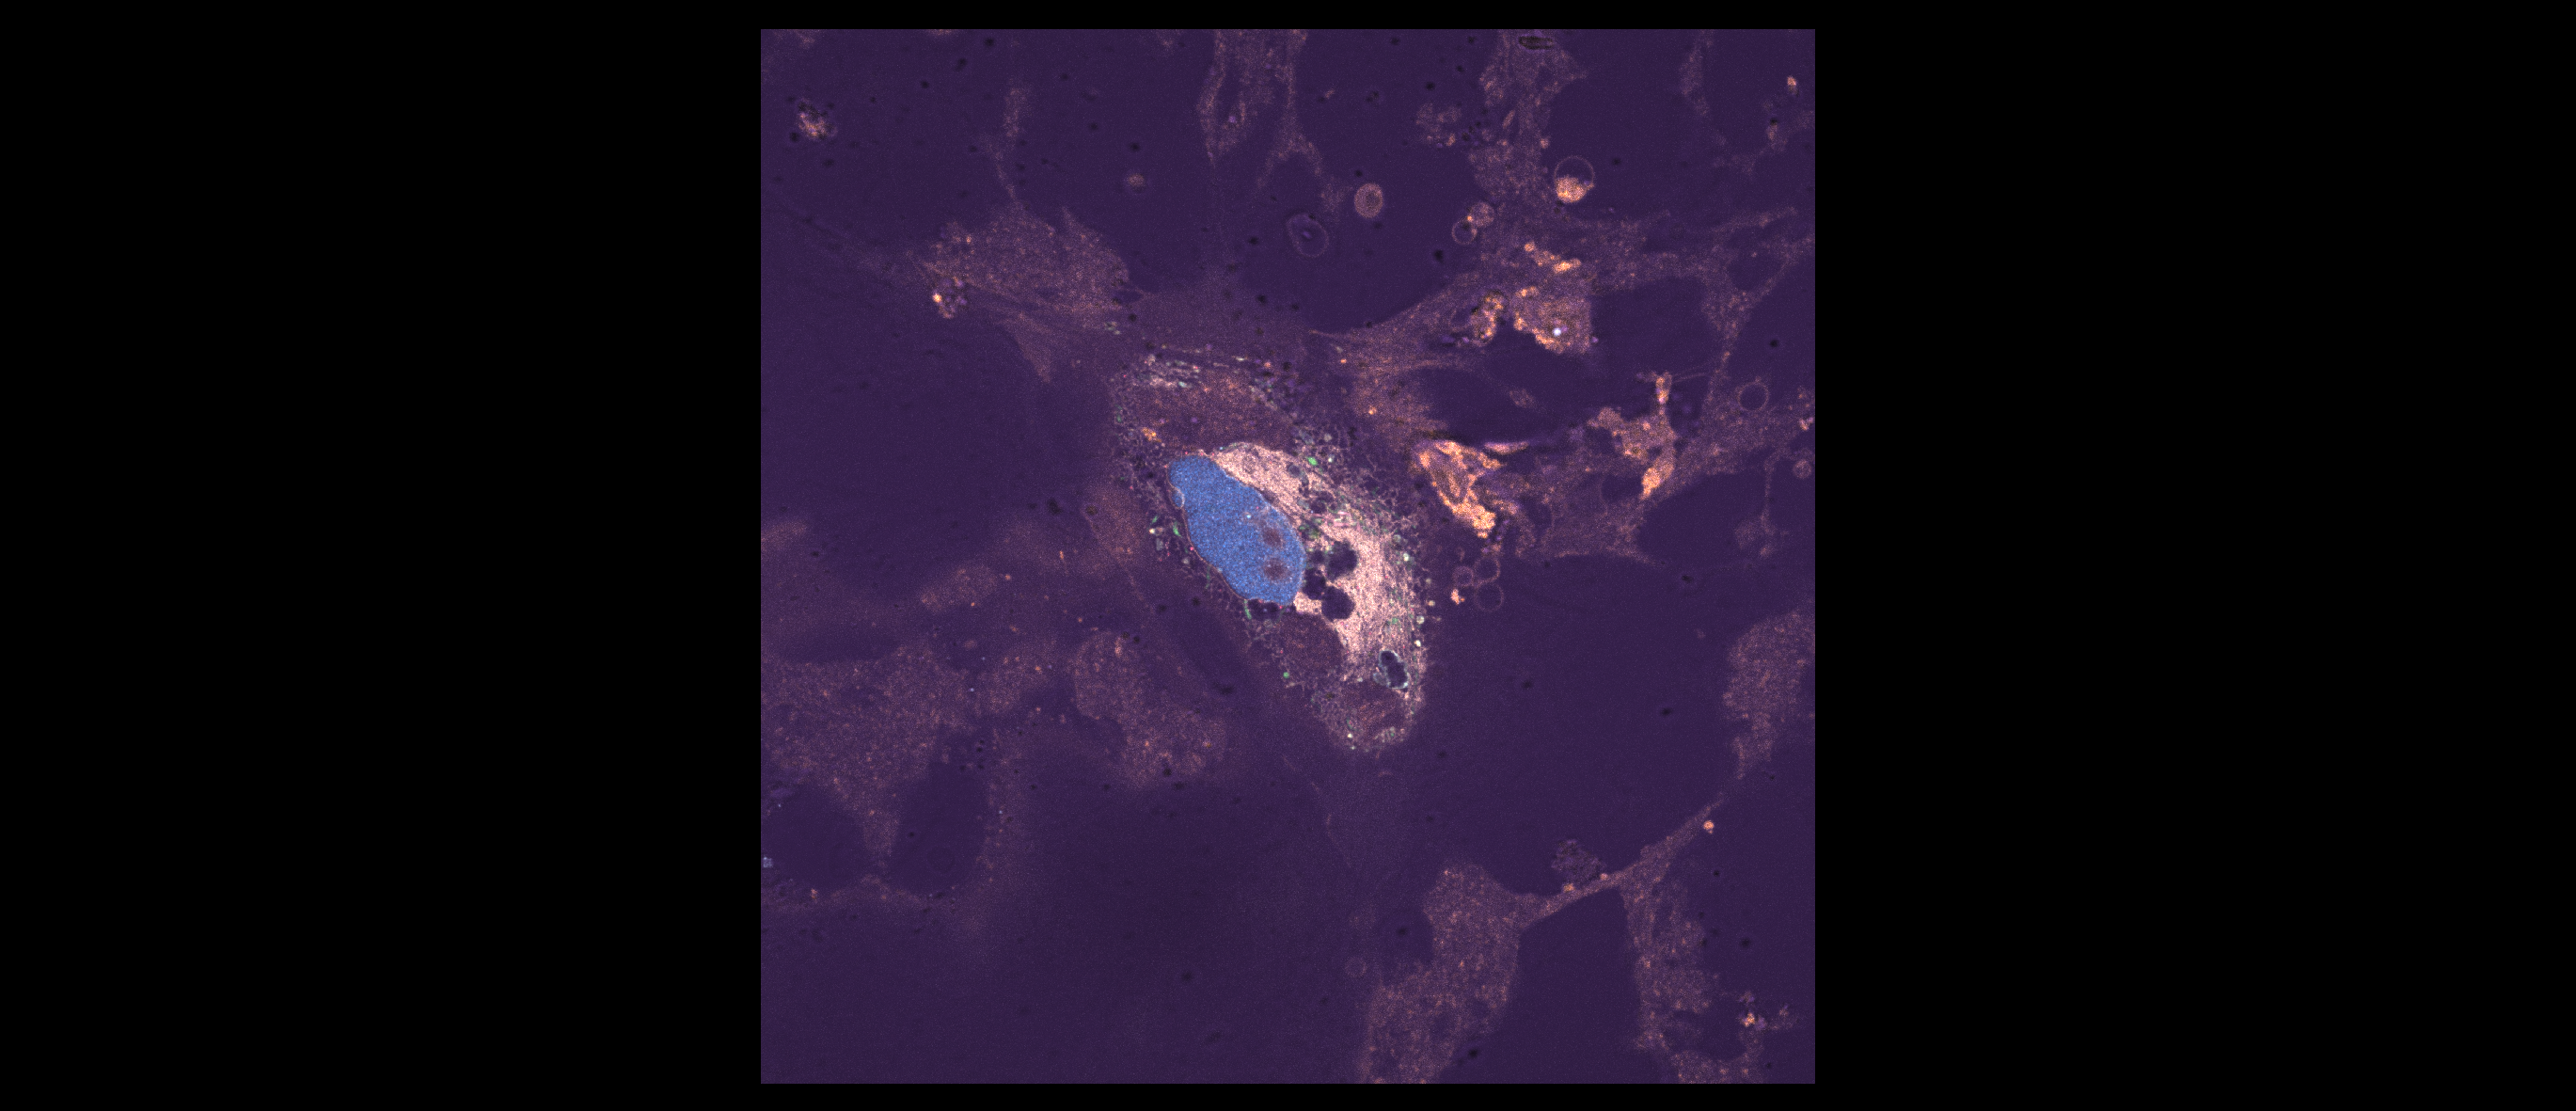

In [29]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']
file_name = str(meta_dict['file_name']).split("\\")[-1]

print("Metadata information")
print(f"File path: {file_path}")
print(f"File name: {file_name}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
for i in list(range(len(channel_names))):
    # add image to viewer
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending='additive',
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

-----
-----
# **ALTERNATIVE: Cellpose 3D segmentation of `Cellmask` and `Nucleus`**

This section segments the cell mask and nuclei with the **pretrained Cellpose models** (`cyto3` for cells, `nuclei` for nuclei) in true 3D, following the approach of [3D Organoid Analysis](https://github.com/bnsreenu/3D-Organoid-Analysis/blob/main/3D_Organoid_Segmentation_Complete.ipynb). The plasma membrane channel (default channel 7) and the nuclear channel (default channel 1) of the image loaded above are used.

It is an alternative to the `masks_C` workflow below: run **either** this section **or** the steps below, not both. This section stacks and saves its own output.

**Requirements:** Cellpose 3.x (the `cyto3` and `nuclei` models were removed in Cellpose 4). Install once with `pip install "cellpose<4"`. A GPU is strongly recommended for 3D.

**Using your own trained models:** if you fine-tuned Cellpose in [`NEW_cellpose-training.ipynb`](NEW_cellpose-training.ipynb), set `CP_CELL_MODEL_PATH` and/or `CP_NUC_MODEL_PATH` in the settings cell below to the model path printed there. The matching diameter setting is then ignored. Leave them as `None` to use the pretrained models.


In [30]:
# if using a composite of organelles, specify the weights here, else leave them as 0/None
use_composite = True
invert_pm = True
PM_CH = 7
w0 = 1
w1 = 2
w2 = 3
w3 = 3
w4 = 2
w5 = 2
w6 = 3
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

In [ ]:
# #### USER INPUT REQUIRED #### -- MCZ iPSCs
# CP_NUC_CH = 1             # channel index of the nuclear stain
# CP_PM_CH = 7              # channel index of the plasma membrane stain

# # Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE).
# CP_NUC_DIAMETER = 150      # expected nucleus diameter (pixels in XY)
# CP_CELL_DIAMETER = 500    # expected cell diameter (pixels in XY)

# CP_XY_DOWNSAMPLE = 1      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
# CP_FLOW_THRESHOLD = 0.2   # raise to be more permissive, lower to be stricter
# CP_CELLPROB_THRESHOLD = -3  # lower (e.g. -2) to segment more/larger objects
# CP_MIN_SIZE_NUC = 2000    # minimum nuclei object size (voxels, downsampled image)
# CP_MIN_SIZE_CELL = 5000   # minimum cell object size (voxels, downsampled image) ### avg iPSC ~200,000 voxels
# CP_BATCH_SIZE = 4         # lower if running out of GPU memory


# #### USER INPUT REQUIRED #### -- MG iPSCs
# CP_NUC_CH = 1             # channel index of the nuclear stain
# CP_PM_CH = 7              # channel index of the plasma membrane stain

# # Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE).
# CP_NUC_DIAMETER = 200      # expected nucleus diameter (pixels in XY)
# CP_CELL_DIAMETER = 600    # expected cell diameter (pixels in XY)

# CP_XY_DOWNSAMPLE = 1      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
# CP_FLOW_THRESHOLD = 0.05   # raise to be more permissive, lower to be stricter; lower to prevent cell splitting
# CP_CELLPROB_THRESHOLD = -3  # lower (e.g. -2) to segment more/larger objects; lower to get more cells
# CP_MIN_SIZE_NUC = 2000    # minimum nuclei object size (voxels, downsampled image) ###  MG iPSC is ~600,000 voxels
# CP_MIN_SIZE_CELL = 5000   # minimum cell object size (voxels, downsampled image) ### avg MCZ iPSC ~200,000 voxels;
# CP_BATCH_SIZE = 4         # lower if running out of GPU memory

#### USER INPUT REQUIRED #### -- MG CMs == NOT WORKING GREAT AT ALL
CP_NUC_CH = 1             # channel index of the nuclear stain
CP_PM_CH = 7              # channel index of the plasma membrane stain

# Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE).
CP_NUC_DIAMETER = 200      # expected nucleus diameter (pixels in XY)
CP_CELL_DIAMETER = 1000    # expected cell diameter (pixels in XY)

CP_XY_DOWNSAMPLE = 1      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
CP_FLOW_THRESHOLD = 0.0001   # raise to be more permissive, lower to be stricter; lower to prevent cell splitting
CP_CELLPROB_THRESHOLD = -5  # lower (e.g. -2) to segment more/larger objects; lower to get more cells
CP_MIN_SIZE_NUC = 2000    # minimum nuclei object size (voxels, downsampled image) ###  MG iPSC is ~600,000 voxels
CP_MIN_SIZE_CELL = 50000   # minimum cell object size (voxels, downsampled image) ### avg MCZ iPSC ~200,000 voxels;
CP_BATCH_SIZE = 4         # lower if running out of GPU memory

# Optional: use your own fine-tuned models (trained in NEW_cellpose-training.ipynb) instead of the pretrained ones.
# Paste the model path printed at the end of that notebook, e.g. r"C:\...\cellpose_models\iPSC_cells\models\iPSC_cells_v001"
# Leave as None to use the pretrained models. Use the same XY downsample and input channels you trained with.
CP_CELL_MODEL_PATH = None   # None = pretrained "cyto3"
CP_NUC_MODEL_PATH = None    # None = pretrained "nuclei"


In [32]:
from importlib.metadata import version
import torch
from cellpose import models
from skimage.transform import resize

if int(version('cellpose').split('.')[0]) >= 4:
    raise ImportError('Cellpose >= 4 no longer includes the cyto3/nuclei models. Run: pip install "cellpose<4" and restart the kernel.')

use_gpu = torch.cuda.is_available()
print(f'Cellpose {version("cellpose")}; using GPU: {use_gpu}')

def _prep(vol, factor):
    """rescale intensities to 0-1 and shrink XY by `factor` (ZYX in, ZYX out)"""
    vol = np.asarray(vol, dtype=np.float32)
    p1, p99 = np.percentile(vol, (1, 99.8))
    vol = np.clip((vol - p1) / (p99 - p1 + 1e-8), 0, 1)
    if factor != 1:
        vol = resize(vol, (vol.shape[0], round(vol.shape[1] / factor), round(vol.shape[2] / factor)),
                     order=1, anti_aliasing=True).astype(np.float32)
    return vol

def _restore(labels, shape):
    """upsample a label volume back to `shape` (nearest neighbour)"""
    if labels.shape != shape:
        labels = resize(labels, shape, order=0, anti_aliasing=False, preserve_range=True)
    return labels.astype(np.uint16)

if use_composite:
    pm_vol = _prep(composite, CP_XY_DOWNSAMPLE)     # ZYX
else:
    pm_vol = _prep(img_data[CP_PM_CH], CP_XY_DOWNSAMPLE)     # ZYX
nuc_vol = _prep(img_data[CP_NUC_CH], CP_XY_DOWNSAMPLE)   # ZYX
out_shape = img_data[CP_NUC_CH].shape
anisotropy = scale[0] / (scale[1] * CP_XY_DOWNSAMPLE)    # Z step relative to XY pixel size

common = dict(do_3D=True, z_axis=0, anisotropy=anisotropy,
              flow_threshold=CP_FLOW_THRESHOLD, cellprob_threshold=CP_CELLPROB_THRESHOLD,
              batch_size=CP_BATCH_SIZE)

# nuclei: single channel
if CP_NUC_MODEL_PATH:
    if not Path(CP_NUC_MODEL_PATH).exists():
        raise FileNotFoundError(f'nuclei model file not found: {CP_NUC_MODEL_PATH}')
    print(f'Using custom nuclei model: {CP_NUC_MODEL_PATH}')
    nuc_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_NUC_MODEL_PATH))
else:
    nuc_model = models.CellposeModel(gpu=use_gpu, model_type='nuclei')
# a custom model carries its own object size, so no diameter is passed to it
nuc_raw = nuc_model.eval(nuc_vol, diameter=None if CP_NUC_MODEL_PATH else CP_NUC_DIAMETER, channels=[0, 0], min_size=CP_MIN_SIZE_NUC, **common)[0]

# cells: membrane (channel 1) + nuclei (channel 2) as ZYXC
if CP_CELL_MODEL_PATH:
    if not Path(CP_CELL_MODEL_PATH).exists():
        raise FileNotFoundError(f'cell model file not found: {CP_CELL_MODEL_PATH}')
    print(f'Using custom cell model: {CP_CELL_MODEL_PATH}')
    cell_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_CELL_MODEL_PATH))
else:
    cell_model = models.CellposeModel(gpu=use_gpu, model_type='cyto3')
cell_in = np.stack([pm_vol, nuc_vol], axis=-1)
cell_raw = cell_model.eval(cell_in, diameter=None if CP_CELL_MODEL_PATH else CP_CELL_DIAMETER, channels=[1, 2],
                           channel_axis=3, min_size=CP_MIN_SIZE_CELL, **common)[0]

cellmask_obj = _restore(cell_raw, out_shape)
nuc_all = _restore(nuc_raw, out_shape)

# Give each nucleus the label of the cell it overlaps most; drop nuclei that are not inside any cell.
nuc_obj = np.zeros_like(nuc_all)
inside = (nuc_all > 0) & (cellmask_obj > 0)
if inside.any():
    pairs, counts = np.unique(np.stack([nuc_all[inside], cellmask_obj[inside]]), axis=1, return_counts=True)
    best_cell, best_count = {}, {}
    for (n, c), k in zip(pairs.T, counts):
        if k > best_count.get(n, 0):
            best_cell[n], best_count[n] = c, k
    lut = np.zeros(int(nuc_all.max()) + 1, dtype=np.uint16)
    for n, c in best_cell.items():
        lut[n] = c
    nuc_obj = lut[nuc_all]

print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}; nuclei found: {len(np.unique(nuc_all)) - 1}; '
      f'nuclei kept inside cells: {len(np.unique(nuc_obj)) - 1}')


viewer.add_image(img_data[CP_NUC_CH], scale=scale, name='Nuclei channel', blending='additive', colormap=color_map[CP_NUC_CH])
viewer.add_image(img_data[CP_PM_CH], scale=scale, name='Plasma membrane channel', blending='additive', colormap=color_map[CP_PM_CH])
viewer.add_labels(nuc_obj, scale=scale, name='Cellpose nuclei', opacity=0.5)
viewer.add_labels(cellmask_obj, scale=scale, name='Cellpose cellmask', opacity=0.5)
viewer.grid.enabled = False

Cellpose 3.1.1.3; using GPU: True
Cells found: 31; nuclei found: 324; nuclei kept inside cells: 2


In [ ]:
# viewer.add_labels(nuc_all, scale=scale, name='Cellpose ALL nuclei')


In [ ]:
# # Stack (nucleus, cell) as uint16 and save. stack_masks() casts to uint8, which export_tiff then
# # flattens to binary, so it is not used here: the instance labels must be preserved.
# stack = np.stack([nuc_obj, cellmask_obj], axis=0).astype(np.uint16)
# out_file_n = export_inferred_organelle(stack, 'masks_cellpose', meta_dict, out_data_path)
# print(f'saved to: {out_data_path}')

### Running without nuclei -- only PM or cell fill

In [ ]:
# if using a composite of organelles, specify the weights here, else leave them as 0
use_composite = True
invert_pm = True
PM_CH = 4
w0 = 10
w1 = 10
w2 = 10
w3 = 10
w4 = 0
w5 = 0
w6 = 0
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

In [26]:
#### USER INPUT REQUIRED #### -- KK iAstros
CP_PM_CH = 4              # channel index of the plasma membrane stain

# Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE).
CP_CELL_DIAMETER = 500    # expected cell diameter (pixels in XY)

CP_XY_DOWNSAMPLE = 1      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
CP_FLOW_THRESHOLD = 0.0001   # raise to be more permissive, lower to be stricter; lower to prevent cell splitting
CP_CELLPROB_THRESHOLD = -7  # lower (e.g. -2) to segment more/larger objects; lower to get more cells
CP_MIN_SIZE_CELL = 50000   # minimum cell object size (voxels, downsampled image) ### avg MCZ iPSC ~200,000 voxels;
CP_BATCH_SIZE = 4         # lower if running out of GPU memory

In [27]:
from importlib.metadata import version
import torch
from cellpose import models
from skimage.transform import resize

if int(version('cellpose').split('.')[0]) >= 4:
    raise ImportError('Cellpose >= 4 no longer includes the cyto3/nuclei models. Run: pip install "cellpose<4" and restart the kernel.')

use_gpu = torch.cuda.is_available()
print(f'Cellpose {version("cellpose")}; using GPU: {use_gpu}')

def _prep(vol, factor):
    """rescale intensities to 0-1 and shrink XY by `factor` (ZYX in, ZYX out)"""
    vol = np.asarray(vol, dtype=np.float32)
    p1, p99 = np.percentile(vol, (1, 99.8))
    vol = np.clip((vol - p1) / (p99 - p1 + 1e-8), 0, 1)
    if factor != 1:
        vol = resize(vol, (vol.shape[0], round(vol.shape[1] / factor), round(vol.shape[2] / factor)),
                     order=1, anti_aliasing=True).astype(np.float32)
    return vol

def _restore(labels, shape):
    """upsample a label volume back to `shape` (nearest neighbour)"""
    if labels.shape != shape:
        labels = resize(labels, shape, order=0, anti_aliasing=False, preserve_range=True)
    return labels.astype(np.uint16)



if use_composite:
    pm_vol = _prep(composite, CP_XY_DOWNSAMPLE)     # ZYX
else:
    pm_vol = _prep(img_data[CP_PM_CH], CP_XY_DOWNSAMPLE)     # ZYX
# nuc_vol = _prep(img_data[CP_NUC_CH], CP_XY_DOWNSAMPLE)   # ZYX
out_shape = img_data[CP_PM_CH].shape
anisotropy = scale[0] / (scale[1] * CP_XY_DOWNSAMPLE)    # Z step relative to XY pixel size

common = dict(do_3D=True, z_axis=0, anisotropy=anisotropy,
              flow_threshold=CP_FLOW_THRESHOLD, cellprob_threshold=CP_CELLPROB_THRESHOLD,
              batch_size=CP_BATCH_SIZE)

# nuclei: single channel
# nuc_model = models.CellposeModel(gpu=use_gpu, model_type='nuclei')
# nuc_raw = nuc_model.eval(nuc_vol, diameter=CP_NUC_DIAMETER, channels=[0, 0], min_size=CP_MIN_SIZE_NUC, **common)[0]

# cells: membrane (channel 1) + nuclei (channel 2) as ZYXC
cell_model = models.CellposeModel(gpu=use_gpu, model_type='cyto3')
cell_in = pm_vol
cell_raw = cell_model.eval(cell_in, diameter=CP_CELL_DIAMETER,
                           channel_axis=3, min_size=CP_MIN_SIZE_CELL, **common)[0]

cellmask_obj = _restore(cell_raw, out_shape)
# nuc_all = _restore(nuc_raw, out_shape)

# Give each nucleus the label of the cell it overlaps most; drop nuclei that are not inside any cell.
# nuc_obj = np.zeros_like(nuc_all)
# inside = (nuc_all > 0) & (cellmask_obj > 0)
# if inside.any():
#     pairs, counts = np.unique(np.stack([nuc_all[inside], cellmask_obj[inside]]), axis=1, return_counts=True)
#     best_cell, best_count = {}, {}
#     for (n, c), k in zip(pairs.T, counts):
#         if k > best_count.get(n, 0):
#             best_cell[n], best_count[n] = c, k
#     lut = np.zeros(int(nuc_all.max()) + 1, dtype=np.uint16)
#     for n, c in best_cell.items():
#         lut[n] = c
#     nuc_obj = lut[nuc_all]

print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}')
if use_composite:
    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')
else:
    viewer.add_image(img_data[CP_PM_CH], scale=scale, name='Plasma membrane channel', blending='additive', colormap=color_map[CP_PM_CH])
viewer.add_labels(cellmask_obj, scale=scale, name='Cellpose cellmask', opacity=0.5)
viewer.grid.enabled = False

Cellpose 3.1.1.3; using GPU: True
Cells found: 4


The Cellpose section ends here. The `masks_C` workflow follows.

----------
----------
# **Below if the regular masks_C pipeline with integration for no nuclei**

-----

## **EXTRACTION**

### **`STEP 1` - Create composite image - I**

&#x1F453; **FYI:** This code block creates the **first** composite image of the organelle channels. The intensity of each channel is combined with specified weights.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Invert_PM`: "True" inverts the intensities of the plasma membrane channel when added to the composite image; "False" leaves the intensity values as is when added to the composite image
- `PM_channel`: the index of the channel containing your plasma membrane label. Image indexing begins with 0, not 1. Reference the channel numbers indicated in the Napari window for easy reference.
- `weight_ch0`: the weight of channel 0 (the first channel); a value of 0 will exclude this channel from the compostite; large values will cause this channel to be more prominent in the final composite image
- `weight_ch1`: the weight of channel 1
- `weight_ch2`: the weight of channel 2
- `weight_ch3`: the weight of channel 3
- `weight_ch4`: the weight of channel 4
- `weight_ch5`: the weight of channel 5
- `weight_ch6`: the weight of channel 6
- `weight_ch7`: the weight of channel 7
- `weight_ch8`: the weight of channel 8
- `weight_ch9`: the weight of channel 9

In [ ]:
# #### USER INPUT REQUIRED ###
# invert_pm_I = True
# PM_CH = 4
# w0_I = 0
# w1_I = 12
# w2_I = 4
# w3_I = 20
# w4_I = 15
# w5_I = 0
# w6_I = 0
# w7_I = 0
# w8_I = 0
# w9_I = 0

#### USER INPUT REQUIRED ### MCZ
invert_pm_II = True
PM_CH = 0
w0_II = 0
w1_II = 2
w2_II = 2
w3_II = 2
w4_II = 2
w5_II = 2
w6_II = 5
w7_II = 5
w8_II = 0
w9_II = 0

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block creates the composite based on the settings above. The image is then added to Napari as a new layer for visual comparison to the input image. 

Use the Napari viewer to iteratively adjust the weights selected above.

In [ ]:
# make aggregate
struct_img_raw_I = membrane_composite(img_data,
                                weight_ch0= w0_I,
                                weight_ch1= w1_I,
                                weight_ch2= w2_I,
                                weight_ch3= w3_I,
                                weight_ch4= w4_I,
                                weight_ch5= w5_I,
                                weight_ch6= w6_I,
                                weight_ch7= w7_I,
                                weight_ch8= w8_I,
                                weight_ch9= w9_I,
                                Invert_PM = invert_pm_I,
                                PM_Channel = PM_CH)

# adding image to Napari as a new layer
viewer.grid.enabled = False
viewer.reset_view()
viewer.add_image(struct_img_raw_I, scale=scale, name="1-Cell: Create composite I")

### **`STEP 2` - Create composite image - II**

&#x1F453; **FYI:** This code block creates the **second** composite image of the organelle channels. The intensity of each channel is combined with specified weights.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Invert_PM`: "True" inverts the intensities of the plasma membrane channel when added to the composite image; "False" leaves the intensity values as is when added to the composite image
- `PM_channel`: the index of the channel containing your plasma membrane label. Image indexing begins with 0, not 1. Reference the channel numbers indicated in the Napari window for easy reference.
- `weight_ch0`: the weight of channel 0 (the first channel); a value of 0 will exclude this channel from the compostite; large values will cause this channel to be more prominent in the final composite image
- `weight_ch1`: the weight of channel 1
- `weight_ch2`: the weight of channel 2
- `weight_ch3`: the weight of channel 3
- `weight_ch4`: the weight of channel 4
- `weight_ch5`: the weight of channel 5
- `weight_ch6`: the weight of channel 6
- `weight_ch7`: the weight of channel 7
- `weight_ch8`: the weight of channel 8
- `weight_ch9`: the weight of channel 9

In [ ]:
# #### USER INPUT REQUIRED ###
# invert_pm_II = False
# PM_CH = 4
# w0_II = 0
# w1_II = 12
# w2_II = 4
# w3_II = 20
# w4_II = 0
# w5_II = 0
# w6_II = 0
# w7_II = 0
# w8_II = 0
# w9_II = 0

#### USER INPUT REQUIRED ### MCZ
invert_pm_II = True
PM_CH = 0
w0_II = 0
w1_II = 2
w2_II = 2
w3_II = 2
w4_II = 2
w5_II = 2
w6_II = 5
w7_II = 5
w8_II = 0
w9_II = 0

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block creates the composite based on the settings above. The image is then added to Napari as a new layer for visual comparison to the input image. 

Use the Napari viewer to iteratively adjust the weights selected above.

In [ ]:
# make aggregate and optionally rescale
struct_img_raw_II = membrane_composite(img_data,
                                weight_ch0= w0_II,
                                weight_ch1= w1_II,
                                weight_ch2= w2_II,
                                weight_ch3= w3_II,
                                weight_ch4= w4_II,
                                weight_ch5= w5_II,
                                weight_ch6= w6_II,
                                weight_ch7= w7_II,
                                weight_ch8= w8_II,
                                weight_ch9= w9_II,
                                Invert_PM = invert_pm_II,
                                PM_Channel = PM_CH)

# adding image to Napari as a new layer
viewer.add_image(struct_img_raw_II, scale=scale, name="2-Cell: Create composite II")

-----
## **PRE-PROCESSING**

### **`STEP 3` - Close gaps and apply filters – I**

&#x1F453; **FYI:** Based on the selected method, this step can either apply a closing algorithm (dilate -> erode) to remove small holes and cracks, or apply a log transform and [Scharr](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.scharr) edge dectection . If Method = `"Ball"` or `"Disk"`, then a closing algorithm will be performed on the composite I image using the footprint specified by the method and size. If Method = `"Scharr"`, then the log-transformation and [Scharr](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.scharr) edge detection is applied to the composite I image. This also means that the size parameter is disregarded.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Method`: "Ball" or "Disk" applies the closing algorithm, "Scharr" applies Scharr edge detection
- `Size`: size of the footprint used in the closing algorithm

In [ ]:
#### USER INPUT REQUIRED ###
method_I = "Disk"
size_I = 5

In [ ]:
# apply closing or the scharr edge detection filter
composite_mask_I = close_and_filter(struct_img_raw_I,
                                    Method = method_I,
                                    Size = size_I)

# adding image to Napari as a new layer
viewer.add_image(composite_mask_I, scale=scale, name="3-Cell: Closing/Scharr I")

### **`STEP 4` - Close gaps and apply filters – II**

&#x1F453; **FYI:** Based on the selected method, this step can either apply a closing algorithm (dilate -> erode) to remove small holes and cracks, or apply a log transform and [Scharr](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.scharr) edge dectection . If Method = `"Ball"` or `"Disk"`, then a closing algorithm will be performed on the composite II image using the footprint specified by the method. If Method = `"Scharr"`, then the log-transformation and [Scharr](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.scharr) edge detection is applied to the composite II image. This also means that the `size` parameter is disregarded.

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Method`: "Ball" or "Disk" applies the closing algorithm, "Scharr" applies Scharr edge detection
- `Size`: size of the footprint used in the closing algorithm

In [ ]:
#### USER INPUT REQUIRED ###
method_II = "Scharr"
size_II = 0

In [ ]:
# apply closing or the scharr edge detection filter
composite_mask_II = close_and_filter(struct_img_raw_II,
                                    Method = method_II,
                                    Size = size_II)

# adding image to Napari as a new layer
viewer.add_image(composite_mask_II, scale=scale, name="4-Cell: Closing/Scharr II")

-----
## **CORE-PROCESSING**

### **`STEP 5` - Threshold object and restrict to PM - I**

&#x1F453; **FYI:** This code block creates a semantic segmentation of a portion of the cell area (capturing certain aspects of the cell). `Semantic segmentation` is the process of deciding whether a pixel/voxel should be included in an object (labeled with a value of 1) or should be considered as part of the background (labeled with a value of 0). When performed on the output of Step 3, this results in the mask_I segmentation. A semantic segmentation does not discern individual objects from one another.

The masked_object_filter utilizes the 'MO' filter from the [`aics-segmentation`](https://github.com/AllenCell/aics-segmentation) package. AICS documentation states: "The algorithm is a hybrid thresholding method combining two levels of thresholds. The steps are: [1] a global threshold is calculated, [2] extract each individual connected componet after applying the global threshold, [3] remove small objects, [4] within each remaining object, a local Otsu threshold is calculated and applied with an optional local threshold adjustment ratio (to make the segmentation more and less conservative). An extra check can be used in step [4], which requires the local Otsu threshold larger than 1/3 of global Otsu threhsold and otherwise this connected component is discarded."

If Bind_To_PM = `"True"`, the plasma membrane channel can be log-transformed and have an Otsu threshold can be applied to produce a plasma membrane segmentation. This can then be inverted and combined with the intial mask_I segmentation to create a mask_I segmentation that is restricted to the plasma membrane boundary. If Bind_To_PM = `"False"`, this additional step is skipped.

#### &#x1F6D1; &#x270D; **User Input Required:**

- `global_method`: the type of thresholding method to be performed globally (MO)
- `cutoff_size`: the minimum object size to advance to the local thresholding step (MO)
- `local_adjust`: the ratio applied to the local Otsu threshold (MO)
- `Bind_To_PM`: Whether to restrict the mask_I segmentation to the inverted plasma membrane segmentation
- `PM_Channel`: the index of the plasma membrane channel (Please note that the first channel is indexed as 0)
- `Thresh_Adj`: The ratio applied to the Otsu threshold of the plasma membrane


In [ ]:
#### USER INPUT REQUIRED ###
global_method_I = "ave"
cutoff_size_I = 0
local_adj_I = 1.0
bind_to_pm_I = True
PM_CH = 7
thresh_adj_I = 1.0

In [ ]:
# Create mask I segmentation (optional to bind to plasma membrane)
mask_I_segmentation = masked_object_thresh_bind_pm(
    img_data,
    composite_mask_I,
    Global_Method = global_method_I,
    Cutoff_Size = cutoff_size_I,
    Local_Adjust = local_adj_I,
    Bind_to_PM = bind_to_pm_I,
    PM_Channel = PM_CH,
    Thresh_Adj = thresh_adj_I)

# adding image to Napari as a new layer
viewer.add_image(mask_I_segmentation, scale=scale, name="5-Cell: MO Thresholding I")

### **`STEP 6` - Threshold object and restrict to PM - II**

&#x1F453; **FYI:** TThis code block creates a semantic segmentation of a portion of the cell area (capturing certain aspects of the cell). `Semantic segmentation` is the process of deciding whether a pixel/voxel should be included in an object (labeled with a value of 1) or should be considered as part of the background (labeled with a value of 0). When performed on the output of Step 4, this results in the mask_II segmentation. A semantic segmentation does not discern individual objects from one another.

The masked_object_filter utilizes the 'MO' filter from the [`aics-segmentation`](https://github.com/AllenCell/aics-segmentation) package. AICS documentation states: "The algorithm is a hybrid thresholding method combining two levels of thresholds. The steps are: [1] a global threshold is calculated, [2] extract each individual connected componet after applying the global threshold, [3] remove small objects, [4] within each remaining object, a local Otsu threshold is calculated and applied with an optional local threshold adjustment ratio (to make the segmentation more and less conservative). An extra check can be used in step [4], which requires the local Otsu threshold larger than 1/3 of global Otsu threhsold and otherwise this connected component is discarded."

If Bind_To_PM = `"True"`, the plasma membrane channel can be log-transformed and have an Otsu threshold can be applied to produce a plasma membrane segmentation. This can then be inverted and combined with the intial mask_II segmentation to create a mask_II segmentation that is restricted to the plasma membrane boundary. If Bind_To_PM = `"False"`, this additional step is skipped.

#### &#x1F6D1; &#x270D; **User Input Required:**

- `global_method`: the type of thresholding method to be performed globally (MO)
- `cutoff_size`: the minimum object size to advance to the local thresholding step (MO)
- `local_adjust`: the ratio applied to the local Otsu threshold (MO)
- `Bind_To_PM`: Whether to restrict the mask_II segmentation to the inverted plasma membrane segmentation
- `PM_Channel`: the index of the plasma membrane channel (Please note that the first channel is indexed as 0)
- `Thresh_Adj`: The ratio applied to the Otsu threshold of the plasma membrane


In [ ]:
#### USER INPUT REQUIRED ###
global_method_II = "ave_tri_med"
cutoff_size_II = 0
local_adj_II = 1.0
bind_to_pm_II = False
PM_CH = 7
thresh_adj_II = 1.0

In [ ]:
# Create mask I segmentation (optional to bind to plasma membrane)
mask_II_segmentation = masked_object_thresh_bind_pm(
    img_data,
    composite_mask_II,
    Global_Method = global_method_II,
    Cutoff_Size = cutoff_size_II,
    Local_Adjust = local_adj_II,
    Bind_to_PM = bind_to_pm_II,
    PM_Channel = PM_CH,
    Thresh_Adj = thresh_adj_II)

# adding image to Napari as a new layer
viewer.add_image(mask_II_segmentation, scale=scale, name="6-Cell: MO Thresholding II")

-----
## **POST-PROCESSING**

### **`STEP 7` - Find the nucleus corresponding to the cell** <mark> **FROM MCZ/ZC** </mark>

MCZ and ZC developed a nuclei-less pipeline c that uses the logic from pipeline a/b to segment the nuclei from the inverse of the cytoplasm segmentation.

In [ ]:
agg = make_aggregate(img_in=img_data,
                     weight_ch0 = 0,
                     weight_ch1= 0,
                     weight_ch2= 0,
                     weight_ch3= 0,
                     weight_ch4= 0,
                     weight_ch5= 0,
                     weight_ch6= 5,
                     weight_ch7= 0,
                     weight_ch8= 0,
                     weight_ch9= 0,
                    rescale= True)

viewer.add_image(agg, name="cytoplasm_aggregate", scale=scale)

In [ ]:
sns = scale_and_smooth(img_in=agg,
                    median_size= 1,
                    gauss_sigma= 1.34,
                    slice_by_slice= False)

viewer.add_image(sns, name="scaled_and_smoothed", scale=scale)

In [ ]:
nlct = non_linear_cellmask_transform(sns)

viewer.add_image(nlct, name="non_linear_cellmask_transform", scale=scale)

In [ ]:
mot = masked_object_thresh(structure_img_smooth= nlct,
                        global_method='ave',
                        cutoff_size=50,
                        local_adjust=0.5)

viewer.add_image(mot, name="masked_object_thresh", scale=scale)

In [ ]:
fafls = fill_and_filter_linear_size(img=mot,
                                hole_min=0,
                                hole_max=10,
                                min_size=50,
                                method="3D",
                                connectivity= 1)

viewer.add_image(fafls, name="fill_and_filter_linear_size", scale=scale)

In [ ]:
infc = infer_nuclei_fromcytoplasm(cytoplasm_mask=fafls, 
                                  nuc_min_hole_w=0,
                                  nuc_max_hole_w=200, 
                                  nuc_fill_method="3D", 
                                  small_obj_w=20,
                                  fill_filter_method="3D")

viewer.add_image(infc, name="infer_nuclei_from_cytoplasm", scale=scale)

In [ ]:
# remove object touching the edge of the image using skimage or scikit-image packages
from skimage.segmentation import clear_border
import numpy as np


# add padding to the Z axis on both sides of the image to avoid clearing objects touching the top/bottom
padding = 1  # number of slices to pad on each side
infc_padded = np.pad(infc, ((padding, padding), (0, 0), (0, 0)), mode='constant', constant_values=0)
viewer.add_image(infc_padded, name="padded", scale=scale)



# clearing
nuc_obj_padded = clear_border(infc_padded, buffer_size=padding)
viewer.add_image(nuc_obj_padded, name="cleared borders", scale=scale)

# remove padding
nuc_obj = nuc_obj_padded[padding:-padding, :, :]
viewer.add_image(nuc_obj, name="cleared borders removed", scale=scale)


# if there is more than one object remaining, throw an error
if np.unique((nuc_obj)).size > 2: raise ValueError("More than one object remaining after clearing borders")

### **`STEP 7` - Find the nucleus corresponding to the cell** <mark> **OLD** </mark>

&#x1F453; **FYI:** This step creates a semantic segmentation of the nucleus using the nuclei channel. First the nuclei intensities are blurred and then log transformed, leading to a nuclei segmentation using [Li's Minimum Cross Entropy](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.threshold_li) method. If there are multiple nuclei objects, then a search image is used to determine which nucleus is the target. The Search_Img can be set to `"Img 5"` (mask_I segmentation) or `"Img 6"` (mask_II segmentation). The nucleus label with the most overlap with the search image is selected as the nucleus object.

#### **`A. Select channel`**

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify which channel includes your nuclei label:
- `NUC_CH`: the index of the channel containing your nuclei label. Image indexing begins with 0, not 1. Reference the channel numbers indicated in the Napari window for easy reference.

In [ ]:
#### USER INPUT REQUIRED ###
NUC_CH = 0

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block extracts the nuclei channel from your multi-channel image. It will be the only part of the image used in the rest of this workflow. The single nuclei channel is added to the Napari viewer.

In [ ]:
# select channel
raw_nuclei = select_channel_from_raw(img_data, NUC_CH)

# add single channel as a new layer
viewer.add_image(raw_nuclei, scale=scale, name="7-Nuc: Extract Channel")

#### **`B. Rescale and smooth image`**

&#x1F453; **FYI:** This code block rescales the image so that the pixel/voxel with the highest intensity is set to 1 and the one with the lowest intensity is set to 0. The image is then *optionally* smoothed using a Gaussian and/or median filter. 

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the amount of filter to use for each method. Higher values indicate more smoothing:
- `med_filter_size`: the size of the median filter to apply; if 0 is used, no filter will be applied
- `gaussian_smoothing_sigma`: the sigma to apply in the Gaussian filtering step; if 0 is used, no filter will be applied

In [ ]:
#### USER INPUT REQUIRED ###
nuc_med_filter_size = 10
nuc_gaussian_smoothing_sigma = 3.0

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block rescales the image and applies the specified median and Gaussian filters. The image is then added to Napari as a new layer for visual comparison to the input image. 

Use the Napari viewer to iteratively adjust the smoothing settings selected above.

In [ ]:
# rescaling and smoothing input image
nuclei =  scale_and_smooth(raw_nuclei,
                           median_size = nuc_med_filter_size, 
                           gauss_sigma = nuc_gaussian_smoothing_sigma)

# adding image to Napari as a new layer
viewer.add_image(nuclei, scale=scale, name="7-Nuc: Rescale and Smooth")

#### **`C. Apply log transform and threshold`**

&#x1F453; **FYI:** This code block applies a log transform and creates semantic segmentation using [Li's Minimum Cross Entropy](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.threshold_li) method. `Semantic segmentation` is the process of deciding whether a pixel/voxel should be included in an object (labeled with a value of 1) or should be considered as part of the background (labeled with a value of 0). A semantic segmentation does not discern individual objects from one another.


#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information:
- `threshold_factor`: adjustment to make to the intial local threshold; larger values make the segmentation more stringent (less area included)
- `thresh_min`: minimum bound of the local threshold
- `thresh_max`: maximum bound of the local threshold

In [ ]:
#### USER INPUT REQUIRED ###
nuc_threshold_factor = 0.9
nuc_thresh_min = .12
nuc_thresh_max = 1.0

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block executes the log transform and threshold using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed.

In [ ]:
# log transform the image, calculate the threshold value using Li minimum cross entropy method, inverse log transform the value
li_thresholded = apply_log_li_threshold(nuclei, 
                                        thresh_factor=nuc_threshold_factor, 
                                        thresh_min=nuc_thresh_min, 
                                        thresh_max=nuc_thresh_max)

# adding image to Napari as a new layer
viewer.add_image(li_thresholded, scale=scale, name="7-Nuc: Threshold", opacity=0.3, colormap="cyan", blending='additive')

#### **`D. Remove small holes and objects`**

&#x1F453; **FYI:** This code block cleans up the semantic segmentation by filling small holes and/or removing small objects that can be considered errors in the initial segmentation. 

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `hole_min_width`: the width of the smallest hole to be filled
- `hole_max_width`: the width of the largest hole to be filled
- `small_object_width`: the width of the largest object to be removed; any object smaller than this size will be removed
- `fill_filter_method`: "3D" processes the image taking into account segmentation values in three dimensions (XYZ); "slice-by-slice" processes each Z-slice in the image separately, not considering the segmentation results in higher or lower Z planes.

In [ ]:
#### USER INPUT REQUIRED ###
nuc_hole_min_width = 0
nuc_hole_max_width = 25  

nuc_small_object_width = 15

nuc_fill_filter_method = "3D"

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block executes the dot filter using the settings above.

Use the Napari viewer to iteratively adjust the filter settings as needed. 

*Hint: white pixels/voxels are the ones remaining after this step*

In [ ]:
# combine the above functions into one for downstream use in plugin
cleaned_img = fill_and_filter_linear_size(li_thresholded, 
                                           hole_min=nuc_hole_min_width, 
                                           hole_max=nuc_hole_max_width, 
                                           min_size=nuc_small_object_width,
                                           method=nuc_fill_filter_method)

# adding image to Napari as a new layer
viewer.add_image(cleaned_img, scale=scale, name="7-Nuc: Fill holes and remove small objects", colormap="magenta", blending="additive")

#### **`E. - Label objects`**

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block takes the semantic segmentation and creates an `instance segmentation`. In this output, each individual object in the image is given a unique ID number. The background pixels/voxels are still labeled as 0, but now each pixle/voxel within an object is labeled as a positive integer. 

In this workflow objects are separated based on connectivity: if a pixel/voxel is touching another pixel/voxel in any direction, they are considered the same object and each pixel/voxel within that object is labeled as the same unique ID number. 

*In the Napari viewer, the image is added as a "labels" layer where each object appears as a different color.*

In [ ]:
# create instance segmentation based on connectivity
nuclei_labels = label_uint16(cleaned_img)

# adding image to Napari as a new layer
viewer.add_labels(nuclei_labels, scale=scale, name="7-Nuc: Instance segmentation")

#### **`F. - Use search image to select single nucleus`**

&#x1F453; **FYI:** This code selects a single nucleus label based on which label has the most overlap with the search image.

#### &#x1F6D1; &#x270D; **User Input Required:**

- `Search_Img`: the image/segmentation used to select the nucleus based on its intensities (“Img 5” refers to the mask_I segmentation image and “Img 6” refers to the mask_II segmentation image)

In [ ]:
#### USER INPUT REQUIRED ###
Search_Img = "Img 6"

In [ ]:
# Collect search image
if Search_Img == "Img 5":
    in_img = mask_I_segmentation
elif Search_Img == "Img 6":
    in_img = mask_II_segmentation

# select single label
keep_nuc = get_max_label((in_img), dilation(nuclei_labels))

# create blank image
nuc_obj = np.zeros_like(nuclei_labels)

# finalize output
nuc_obj[nuclei_labels == keep_nuc] = 1

# adding image to Napari as a new layer
viewer.add_labels(nuc_obj, scale=scale, name="7-Nuc: Select single nucleus")

### **`STEP 8` - Combine nucleus and thresh and fill holes - I**

&#x1F453; **FYI:** This performs a logical **OR** of the nucleus object (can be dilated) and the mask_I_segmentation. After the two segmentations are combined, small objects and holes can be removed. The result of this step is the cellmask_I segmentation.

- To dilate the nucleus in 3D, set Method = `'Ball'`
- To dilate the nucleus in 2D, set Method = `'Disk'`
- To skip dilation, set Method = `'None'`
###### (the string `"None"` is **not** to be confused with the `None` object)

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Method`: the footprint of the nucleus dilation, "Ball" or "Disk" applies dilation, "None" skips dilation
- `Size`: size of the footprint in the nucleus dilation
- `Min_Hole_Width`: the minimum hole width to be filled in the combined segmentation
- `Max_Hole_Width`: the maximum hole width to be filled in the combined segmentation
- `Small_Obj_Width`: the minimum width of the objects to remain in the combined segmentation

In [ ]:
# cm stands for cellmask, helps distinguish variables
cm_method_I = "Ball"
cm_size_I = 0
cm_min_hole_width_I = 0
cm_max_hole_width_I = 50
cm_small_obj_width_I = 1

In [ ]:
# create cellmask_I segmentation
cellmask_I_seg = mix_nuc_and_fill(nuc_obj,
                 mask_I_segmentation,
                 Method = cm_method_I,
                 Size = cm_size_I,
                 Min_Hole_Width = cm_min_hole_width_I,
                 Max_Hole_Width = cm_max_hole_width_I,
                 Small_Obj_Width = cm_small_obj_width_I)

# adding image to Napari as a new layer
viewer.add_image(cellmask_I_seg, scale=scale, name="8-Cell: Combine nuc and thresh I")

### **`STEP 9` - Combine nucleus and thresh and fill holes - II**

&#x1F453; **FYI:** This performs a logical **OR** of the nucleus object (can be dilated) and the mask_II_segmentation. After the two segmentations are combined, small objects and holes can be removed. The result of this step is the cellmask_II segmentation.

- To dilate the nucleus in 3D, set Method = `'Ball'`
- To dilate the nucleus in 2D, set Method = `'Disk'`
- To skip dilation, set Method = `'None'`, (the string `"None"` **not** the `None` object)

###### (the string `"None"` is **not** to be confused with the `None` object)

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Method`: the footprint of the nucleus dilation, "Ball" or "Disk" applies dilation, "None" skips dilation
- `Size`: size of the footprint in the nucleus dilation
- `Min_Hole_Width`: the minimum hole width to be filled in the combined segmentation
- `Max_Hole_Width`: the maximum hole width to be filled in the combined segmentation
- `Small_Obj_Width`: the minimum width of the objects to remain in the combined segmentation

In [ ]:
# cm stands for cellmask, helps distinguish variables
cm_method_II = "Disk"
cm_size_II = 0
cm_min_hole_width_II = 0
cm_max_hole_width_II = 50
cm_small_obj_width_II = 1

In [ ]:
# create cellmask_II segmentation
cellmask_II_seg = mix_nuc_and_fill(nuc_obj,
                 mask_II_segmentation,
                 Method = cm_method_II,
                 Size = cm_size_II,
                 Max_Hole_Width = cm_min_hole_width_II,
                 Min_Hole_Width = cm_max_hole_width_II,
                 Small_Obj_Width = cm_small_obj_width_II)

# adding image to Napari as a new layer
viewer.add_image(cellmask_II_seg, scale=scale, name="9-Cell: Combine nuc and thresh II")

-----
## **POST-POST-PROCESSING**

### **`STEP 10` - Watershed for cellmask**

&#x1F453; **FYI:** This step peforms two [watershed](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.watershed) algorithms and then combines the results of both using a logical **OR**. 

For each iteration, the watershed is performed on the mask segmentation (I or II) which is bounded by its respective cellmask segmentation (I or II). To perform the watershed in 3D, set Watershed_Method = `"3D"`, or set Watershed_Method = `"slice_by_slice"` to run it in 2D. Also note that in both iterations, the seed is nucleus segmentation from step 7.

Next, a logical **OR** is used to combine both segmentations to produce an unfinished cellmask. For final touches, the cellmask undergoes a closing (dilation -> erosion) algorithm. Closing can be performed in 3D if Method = `'Ball'`, or 2D if Method = `'Disk'`. Alternatively, the closing algorithm can be skipped altogether if Method = `'None'`. Small objects will be removed after the dilation, but before the erosion.

###### (the string `"None"` is **not** to be confused with the `None` object)

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following values:
- `Watershed_Method`: whether to perform the watershed on a “3D” level or on a 2D level (“slice_by_slice”)
- `Method`: the footprint of the cellmask closing, "Ball" or "Disk" applies dilation, "None" skips closing
- `Size`: size of the footprint in the cellmask closing
- `Min_Hole_Width`: the minimum hole width to be filled in the cellmask
- `Max_Hole_Width`: the maximum hole width to be filled in the cellmask

In [ ]:
# parameters for final cellmask
cm_watershed_method = "3D"
cm_method = "Disk"
cm_size = 15
cm_min_hole_width = 0
cm_max_hole_width = 10000

In [ ]:
cellmask_obj = double_watershed(nuc_obj,
                                mask_I_segmentation,
                                mask_II_segmentation,
                                cellmask_I_seg,
                                cellmask_II_seg,
                                Watershed_Method = cm_watershed_method,
                                Min_Hole_Width = cm_min_hole_width,
                                Max_Hole_Width = cm_max_hole_width,
                                Method = cm_method,
                                Size = cm_size)

# adding image to Napari as a new layer
viewer.add_image(cellmask_obj, scale=scale, name="10-Cell: Watershed for Cellmask")

-----
## **EXPORT**

### **`STEP 11` - Stack masks**

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block stacks the single nucleus and cell masks into one multichannel image.

In [ ]:
stack = stack_masks(nuc_mask = nuc_obj, cellmask = cellmask_obj)
print(f"Stack mask file structure: {np.shape(stack)}")
print(f"The dimension of '2' represents the 'nucleus' and 'cell' in that order.")

-----
## **SAVING**

### **`Saving` - Save the segmentation output**

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block saves the instance segmentation output to the `out_data_path` specified earlier.

In [ ]:
# Saving file
out_file_n = export_inferred_organelle(stack, "masks_C", meta_dict, out_data_path)
print(f"saved to: {out_data_path}")

-----
-----
## **Define functions**
The following code includes an example of how the workflow steps above are combined into functions. The final combined `infer_masks_C` function can be run below to process a single image. It is included in the [batch process notebook](batch_process_segmentations.ipynb) to run the above analysis on multiple cells.

This function can utilized from infer-subc using:
```python
infer_subc.organelles.masks.infer_masks_C()
```

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `_infer_masks_masks_C()`, function. It is applied below.

In [ ]:
##########################
# _infer_intermediate_masks
# alternative workflow "c"
##########################

def _infer_intermediate_masks(in_img: np.ndarray,
                           pm_ch: Union[int,None],
                           weights_I: list[int],
                           weights_II: list[int],
                           invert_pm_I: bool,
                           invert_pm_II: bool,
                           method_I: str,
                           method_II: str,
                           size_I: int,
                           size_II: int,
                           global_method_I: str,
                           global_method_II: str,
                           cutoff_size_I: int,
                           cutoff_size_II: int,
                           local_adj_I: float,
                           local_adj_II: float,
                           bind_to_pm_I: bool,
                           bind_to_pm_II: bool,
                           thresh_adj_I: float,
                           thresh_adj_II: float):
 
    """
    Procedure to infer intermediate masks from linear unmixed input.

    Parameters
    ------------
    in_img: 
        a 3d image containing all the channels
    pm_ch:
        the index of the channel containing your plasma membrane label
    weights_I:
        a list of int that corresond to the weights for each channel in the first composite; use 0 if a channel should not be included in the composite image
    weights_II:
        a list of int that corresond to the weights for each channel in the second composite; use 0 if a channel should not be included in the composite image
    invert_pm_I:
        True = invert plasma membrane channel in the first composite
        False = do not invert plasma membrane channel in the first composite
    invert_pm_II:
        True = invert plasma membrane channel in the second composite
        False = do not invert plasma membrane channel in the second composite
    method_I:
        which footprint shape to use for the closing algorithm on the first composite. Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "Scharr" (skip closing altogether and apply Scharr edge detection).
    method_II:
        which footprint shape to use for the closing algorithm on the second composite. Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "Scharr" (skip closing altogether and apply Scharr edge detection).
    size_I:
        size of the footprint used in closing algorithm on the first composite, this value is disregarded if method_I == "Scharr"
    size_II:
        size of the footprint used in closing algorithm on the second composite, this value is disregarded if method_II == "Scharr"
    global_method_I:
         which method to use for calculating global threshold applied to composite_mask_I (MO). Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    global_method_II:
         which method to use for calculating global threshold applied to composite_mask_II (MO). Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    cutoff_size_I: 
        Masked Object threshold `size_min`; minimum size of of object to advanced to the local Otsu thresholding
        step in the Masked Object thresholding of composite_mask_I.
    cutoff_size_II: 
        Masked Object threshold `size_min`; minimum size of of object to advanced to the local Otsu thresholding
        step in the Masked Object thresholding of composite_mask_II.
    local_adj_I: 
        Masked Object threshold `local_adjust`, proportion applied to the local Otsu threshold (composite_mask_I MO thresholding)
    local_adj_II: 
        Masked Object threshold `local_adjust`, proportion applied to the local Otsu threshold (composite_mask_II MO thresholding)
    bind_to_pm_I:
        True = restrict the resulting mask_I_segmentation to the thresholded plasma membrane
        False = do not restrict the resulting mask_I_segmentation to the thresholded plasma membrane
    bind_to_pm_II:
        True = restrict the resulting mask_II_segmentation to the thresholded plasma membrane
        False = do not restrict the resulting mask_II_segmentation to the thresholded plasma membrane
    thresh_adj_I:
        the proportion applied to the Otsu threshold of the plasma membrane (disregarded if bind_to_pm_I == False)
    thresh_adj_II:
        the proportion applied to the Otsu threshold of the plasma membrane (disregarded if bind_to_pm_II == False)
    
    

    Returns
    -------------
    mask_I and mask_II segmentation:
        two logical/labels objects that will be used to find the cellmask

    """

    ###################
    # EXTRACT
    ###################

    struct_img_raw_I = membrane_composite(in_img, *weights_I, invert_pm_I, pm_ch)

    struct_img_raw_II = membrane_composite(in_img, *weights_II, invert_pm_II, pm_ch)

    ###################
    # PRE_PROCESSING
    ###################

    composite_mask_I = close_and_filter(struct_img_raw_I, method_I, size_I)

    composite_mask_II = close_and_filter(struct_img_raw_II, method_II, size_II)

    ###################
    # CORE_PROCESSING
    ###################

    mask_I_segmentation = masked_object_thresh_bind_pm(in_img,
                                                       composite_mask_I,
                                                       global_method_I,
                                                       cutoff_size_I,
                                                       local_adj_I,
                                                       bind_to_pm_I,
                                                       pm_ch,
                                                       thresh_adj_I)
    
    mask_II_segmentation = masked_object_thresh_bind_pm(in_img,
                                                       composite_mask_II,
                                                       global_method_II,
                                                       cutoff_size_II,
                                                       local_adj_II,
                                                       bind_to_pm_II,
                                                       pm_ch,
                                                       thresh_adj_II)
    
    return label_bool_as_uint16(mask_I_segmentation),label_bool_as_uint16(mask_II_segmentation)


#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
# run nuclei segmentation from label
_mask_I_segmentation,_mask_II_segmentation = _infer_intermediate_masks(img_data,
                           PM_CH,
                           [w0_I, w1_I, w2_I, w3_I, w4_I, w5_I, w6_I, w7_I, w8_I, w9_I],
                           [w0_II, w1_II, w2_II, w3_II, w4_II, w5_II, w6_II, w7_II, w8_II, w9_II],
                           invert_pm_I,
                           invert_pm_II,
                           method_I,
                           method_II,
                           size_I,
                           size_II,
                           global_method_I,
                           global_method_II,
                           cutoff_size_I,
                           cutoff_size_II,
                           local_adj_I,
                           local_adj_II,
                           bind_to_pm_I,
                           bind_to_pm_II,
                           thresh_adj_I,
                           thresh_adj_II)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(mask_I_segmentation == _mask_I_segmentation) & np.all(mask_II_segmentation == _mask_II_segmentation)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `_infer_nucleus_masks_C()`, function. It is applied below.

In [ ]:
##########################
# _infer_nucleus_masks_C
# alternative workflow "c"
##########################

def _infer_nucleus_masks_C(in_img: np.ndarray,
                           nuc_ch: Union[int,None],
                           mask_I_segmentation: np.ndarray,
                           mask_II_segmentation: np.ndarray,
                           nuc_med_filter_size: int,
                           nuc_gaussian_smoothing_sigma: float,
                           nuc_threshold_factor: float,
                           nuc_thresh_min: float,
                           nuc_thresh_max: float,
                           nuc_hole_min_width: int,
                           nuc_hole_max_width: int,
                           nuc_small_object_width: int,
                           nuc_fill_filter_method: str,
                           nuc_search_img: str):
    
    """
    Procedure to infer intermediate masks from linear unmixed input.

    Parameters
    ------------
    in_img: 
        a 3d image containing all the channels
    nuc_ch:
        the index of the channel containing your nuclei label
    mask_I_segmentation:
        the first logical/labels object that will be used to find the cellmask
    mask_II_segmentation:
        the second logical/labels object that will be used to find the cellmask
    nuc_med_filter_size: 
        width of median filter for nuclei signal
    nuc_gaussian_smoothing_sigma: 
        sigma for gaussian smoothing of nuclei signal
    nuc_threshold_factor:
        adjustment to make to the intial local threshold of the nucleus singal;
        intital threshold is derived from Li's minimum cross entropy method
    nuc_thresh_min:
        minimum bound of the local threshold of the nucleus
    nuc_thresh_max:
        maximum bound of the local threshold of the nucleus
    nuc_hole_min_width: 
        the minimum hole width to be filled in the nucleus post-thresholding
    nuc_hole_max_width:
        the maximum hole width to be filled in the nucleus post-thresholding
    nuc_small_object_width:
        minimum object size cutoff for nucleus post-thresholding
    nuc_fill_filter_method:
        determines if fill and filter should be run 'sice-by-slice' or in '3D' (nucleus)
    nuc_search_img:
        the segmentation used to select the nucleus based on greatest overlap. Options include:
        "Img 5" (mask_I_segmentation) and "Img 6" (mask_II_segmentation)
    
    Returns
    -------------
    nucleus_object:
        mask defined extent of NU

    """
    ###################
    # POST_PROCESSING
    ###################

    nuc_obj = find_nuc(in_img, 
             mask_I_segmentation,
             mask_II_segmentation,
             nuc_ch,
             nuc_med_filter_size,
             nuc_gaussian_smoothing_sigma,
             nuc_threshold_factor,
             nuc_thresh_min,
             nuc_thresh_max,
             nuc_hole_min_width,
             nuc_hole_max_width,
             nuc_small_object_width,
             nuc_fill_filter_method,
             nuc_search_img)
    
    return label_bool_as_uint16(nuc_obj)

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
# run nuclei segmentation from label
_NU_object = _infer_nucleus_masks_C(img_data,
                           NUC_CH,
                           _mask_I_segmentation,
                           _mask_II_segmentation,
                           nuc_med_filter_size,
                           nuc_gaussian_smoothing_sigma,
                           nuc_threshold_factor,
                           nuc_thresh_min,
                           nuc_thresh_max,
                           nuc_hole_min_width,
                           nuc_hole_max_width,
                           nuc_small_object_width,
                           nuc_fill_filter_method,
                           Search_Img)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(nuc_obj == _NU_object)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `_infer_cellmask_masks_C()`, function. It is applied below.

In [ ]:
##########################
# _infer_cellmask_masks_C
# alternative workflow "c"
##########################
def _infer_cellmask_masks_C(nuc_obj: np.ndarray,
                           mask_I_segmentation: np.ndarray,
                           mask_II_segmentation: np.ndarray,
                           cm_method_I: str,
                           cm_method_II: str,
                           cm_size_I: int,
                           cm_size_II: int,
                           cm_min_hole_width_I: int,
                           cm_min_hole_width_II: int,
                           cm_max_hole_width_I: int,
                           cm_max_hole_width_II: int,
                           cm_small_obj_width_I: int,
                           cm_small_obj_width_II: int,
                           cell_watershed_method: str,
                           cell_min_hole_width: int,
                           cell_max_hole_width: int,
                           cell_method: str,
                           cell_size: int):
    
    """
    Procedure to infer cellmask from linear unmixed input.

    Parameters
    ------------
    nuc_obj:
        a 3d image containing the inferred nucleus object
    mask_I_segmentation:
        the first logical/labels object that will be used to find the cellmask
    mask_II_segmentation:
        the second logical/labels object that will be used to find the cellmask
    cm_method_I:
        which footprint shape to use for the nucleus dilation before combination with the mask_I_segmentation. Options include:
        "Ball" (3D dilation), "Disk" (2D dilation), and "None" (skip dilation altogether).
    cm_method_II:
        which footprint shape to use for the nucleus dilation before combination with the mask_II_segmentation. Options include:
        "Ball" (3D dilation), "Disk" (2D dilation), and "None" (skip dilation altogether).
    cm_size_I:
        size of the footprint used in dilation of the nucleus object, this value is disregarded if cm_method_I == "None"
    cm_size_II:
        size of the footprint used in dilation of the nucleus object, this value is disregarded if cm_method_II == "None"
    cm_min_hole_width_I: 
        the minimum hole width to be filled in the cellmask_I_segmentation
    cm_min_hole_width_II: 
        the minimum hole width to be filled in the cellmask_II_segmentation
    cm_max_hole_width_I: 
        the maximum hole width to be filled in the cellmask_I_segmentation
    cm_max_hole_width_II: 
        the maximum hole width to be filled in the cellmask_II_segmentation
    cm_small_obj_width_I:
        minimum object size cutoff for the cellmask_I_segmentation
    cm_small_obj_width_II:
        minimum object size cutoff for the cellmask_II_segmentation
    cell_watershed_method:
        determines if the watershed should be run 'sice-by-slice' or in '3D'
    cell_min_hole_width: 
        the minimum hole width to be filled in the cellmask object
    cell_max_hole_width: 
        the maximum hole width to be filled in the cellmask object
    cell_method:
        which footprint shape to use for the cellmask closing (dilation -> erosion). Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "None" (skip closing altogether).
    cell_size:
        size of the footprint used in closing of the cellmask object, this value is disregarded if cm_method_I == "None"
        
    
    Returns
    -------------
    cellmask:
        a logical/labels object defining boundaries of cellmask

    """
    ###################
    # POST_PROCESSING
    ###################

    cellmask_I_seg = mix_nuc_and_fill(nuc_obj,
                 mask_I_segmentation,
                 cm_method_I,
                 cm_size_I,
                 cm_min_hole_width_I,
                 cm_max_hole_width_I,
                 cm_small_obj_width_I)
    
    cellmask_II_seg = mix_nuc_and_fill(nuc_obj,
                 mask_II_segmentation,
                 cm_method_II,
                 cm_size_II,
                 cm_min_hole_width_II,
                 cm_max_hole_width_II,
                 cm_small_obj_width_II)
    
    #########################
    # POST- POST_PROCESSING
    #########################

    cellmask_obj = double_watershed(nuc_obj,
                                mask_I_segmentation,
                                mask_II_segmentation,
                                cellmask_I_seg,
                                cellmask_II_seg,
                                cell_watershed_method,
                                cell_min_hole_width,
                                cell_max_hole_width,
                                cell_method,
                                cell_size)
    
    return label_bool_as_uint16(cellmask_obj)

#### &#x1F3C3; **Run code; no user input required**

&#x1F453; **FYI:** This code block applies the function above to your test image. The settings specified above are applied here.

In [ ]:
# run nuclei segmentation from label
_CM_object = _infer_cellmask_masks_C(_NU_object,
                                    _mask_I_segmentation,
                                    _mask_II_segmentation,
                                    cm_method_I,
                                    cm_method_II,
                                    cm_size_I,
                                    cm_size_II,
                                    cm_min_hole_width_I,
                                    cm_min_hole_width_II,
                                    cm_max_hole_width_I,
                                    cm_max_hole_width_II,
                                    cm_small_obj_width_I,
                                    cm_small_obj_width_II,
                                    cm_watershed_method,
                                    cm_min_hole_width,
                                    cm_max_hole_width,
                                    cm_method,
                                    cm_size)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(cellmask_obj == _CM_object)}")

#### &#x1F3C3; **Run code; no user input required**
&#x1F453; **FYI:** This code block defines the `infer_masks_C()`, function, the complete function that combines the three above and that will be used for batch processing. It is applied below.

In [ ]:
def _infer_masks_C(in_img: np.ndarray,
                   pm_ch: Union[int,None],
                   nuc_ch: Union[int,None],
                   parameters_I: list[list, bool, str, int, str, int, float, bool, float, str, int, int, int, int],
                   parameters_II: list[list, bool, str, int, str, int, float, bool, float, str, int, int, int, int],
                   nuc_med_filter_size: int,
                   nuc_gaussian_smoothing_sigma: float,
                   nuc_threshold_factor: float,
                   nuc_thresh_min: float,
                   nuc_thresh_max: float,
                   nuc_hole_min_width: int,
                   nuc_hole_max_width: int,
                   nuc_small_object_width: int,
                   nuc_fill_filter_method: str,
                   nuc_search_img: str,
                   cell_watershed_method: str,
                   cell_min_hole_width: int,
                   cell_max_hole_width: int,
                   cell_method: str,
                   cell_size: int) -> np.ndarray:
    """
    Procedure to infer intermediate masks from linear unmixed input.

    Parameters
    ------------
    in_img: 
        a 3d image containing all the channels
    pm_ch:
        the index of the channel containing your plasma membrane label
    nuc_ch:
        the index of the channel containing your nuclei label
    parameters_I:
        list that contains the following (weights_I, invert_pm_I, method_I, size_I, global_method_I, cutoff_size_I, local_adj_I,
        bind_to_pm_I, thresh_adj_I, cm_method_I,cm_size_I, cm_min_hole_width_I, cm_max_hole_width_I, cm_small_obj_width_I), 
        all of which are related to the first sequence of steps in masks_C
    weights_I:
        a list of int that corresond to the weights for each channel in the first composite; use 0 if a channel should not be included in the composite image
    invert_pm_I:
        True = invert plasma membrane channel in the first composite
        False = do not invert plasma membrane channel in the first composite
    method_I:
        which footprint shape to use for the closing algorithm on the first composite. Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "Scharr" (skip closing altogether and apply Scharr edge detection).
    size_I:
        size of the footprint used in closing algorithm on the first composite, this value is disregarded if method_I == "Scharr"
    global_method_I:
         which method to use for calculating global threshold applied to composite_mask_I (MO). Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    cutoff_size_I: 
        Masked Object threshold `size_min`; minimum size of of object to advanced to the local Otsu thresholding
        step in the Masked Object thresholding of composite_mask_I.
    local_adj_I: 
        Masked Object threshold `local_adjust`, proportion applied to the local Otsu threshold (composite_mask_I MO thresholding)
    bind_to_pm_I:
        True = restrict the resulting mask_I_segmentation to the thresholded plasma membrane
        False = do not restrict the resulting mask_I_segmentation to the thresholded plasma membrane
    thresh_adj_I:
        the proportion applied to the Otsu threshold of the plasma membrane (disregarded if bind_to_pm_I == False)
    cm_method_I:
        which footprint shape to use for the nucleus dilation before combination with the mask_I_segmentation. Options include:
        "Ball" (3D dilation), "Disk" (2D dilation), and "None" (skip dilation altogether).
    cm_size_I:
        size of the footprint used in dilation of the nucleus object, this value is disregarded if cm_method_I == "None"
    cm_min_hole_width_I: 
        the minimum hole width to be filled in the cellmask_I_segmentation
    cm_max_hole_width_I: 
        the maximum hole width to be filled in the cellmask_I_segmentation
    cm_small_obj_width_I:
        minimum object size cutoff for the cellmask_I_segmentation
    parameters_II:
        list that contains the following parameters (weights_II, invert_pm_II, method_II, size_II, global_method_II, cutoff_size_II,
        local_adj_II, bind_to_pm_II, thresh_adj_II, cm_method_II, cm_size_II, cm_min_hole_width_II, cm_max_hole_width_II, 
        cm_small_obj_width_II), all of which are related to the second sequence of steps in masks_C
    weights_II:
        a list of int that corresond to the weights for each channel in the second composite; use 0 if a channel should not be included in the composite image
    invert_pm_II:
        True = invert plasma membrane channel in the second composite
        False = do not invert plasma membrane channel in the second composite
    method_II:
        which footprint shape to use for the closing algorithm on the second composite. Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "Scharr" (skip closing altogether and apply Scharr edge detection).
    size_II:
        size of the footprint used in closing algorithm on the second composite, this value is disregarded if method_II == "Scharr"
    global_method_II:
         which method to use for calculating global threshold applied to composite_mask_II (MO). Options include:
         "triangle" (or "tri"), "median" (or "med"), and "ave_tri_med" (or "ave").
         "ave" refers the average of "triangle" threshold and "mean" threshold.
    cutoff_size_II: 
        Masked Object threshold `size_min`; minimum size of of object to advanced to the local Otsu thresholding
        step in the Masked Object thresholding of composite_mask_II.
    local_adj_II: 
        Masked Object threshold `local_adjust`, proportion applied to the local Otsu threshold (composite_mask_II MO thresholding)
    bind_to_pm_II:
        True = restrict the resulting mask_II_segmentation to the thresholded plasma membrane
        False = do not restrict the resulting mask_II_segmentation to the thresholded plasma membrane
    thresh_adj_II:
        the proportion applied to the Otsu threshold of the plasma membrane (disregarded if bind_to_pm_II == False)
    cm_method_II:
        which footprint shape to use for the nucleus dilation before combination with the mask_II_segmentation. Options include:
        "Ball" (3D dilation), "Disk" (2D dilation), and "None" (skip dilation altogether).
    cm_size_II:
        size of the footprint used in dilation of the nucleus object, this value is disregarded if cm_method_II == "None"
    cm_min_hole_width_II: 
        the minimum hole width to be filled in the cellmask_II_segmentation
    cm_max_hole_width_II: 
        the maximum hole width to be filled in the cellmask_II_segmentation
    cm_small_obj_width_II:
        minimum object size cutoff for the cellmask_II_segmentation
    nuc_med_filter_size: 
        width of median filter for nuclei signal
    nuc_gaussian_smoothing_sigma: 
        sigma for gaussian smoothing of nuclei signal
    nuc_threshold_factor:
        adjustment to make to the intial local threshold of the nucleus singal;
        intital threshold is derived from Li's minimum cross entropy method
    nuc_thresh_min:
        minimum bound of the local threshold of the nucleus
    nuc_thresh_max:
        maximum bound of the local threshold of the nucleus
    nuc_hole_min_width: 
        the minimum hole width to be filled in the nucleus post-thresholding
    nuc_hole_max_width:
        the maximum hole width to be filled in the nucleus post-thresholding
    nuc_small_object_width:
        minimum object size cutoff for nucleus post-thresholding
    nuc_fill_filter_method:
        determines if fill and filter should be run 'sice-by-slice' or in '3D' (nucleus)
    nuc_search_img:
        the segmentation used to select the nucleus based on greatest overlap. Options include:
        "Img 5" (mask_I_segmentation) and "Img 6" (mask_II_segmentation)
    cell_watershed_method:
        determines if the watershed should be run 'sice-by-slice' or in '3D'
    cell_min_hole_width: 
        the minimum hole width to be filled in the cellmask object
    cell_max_hole_width: 
        the maximum hole width to be filled in the cellmask object
    cell_method:
        which footprint shape to use for the cellmask closing (dilation -> erosion). Options include:
        "Ball" (3D closing), "Disk" (2D closing), and "None" (skip closing altogether).
    cell_size:
        size of the footprint used in closing of the cellmask object, this value is disregarded if cm_method_I == "None"
    
    Returns
    -------------
    mask_stack:
        a two channel np.ndarray constisting of the nucleus and cell (one object per channel)

    """
    # Get list of parameters (I and II)
    weights_I, invert_pm_I, method_I, size_I, global_method_I, cutoff_size_I, local_adj_I, bind_to_pm_I, thresh_adj_I, cm_method_I, cm_size_I, cm_min_hole_width_I, cm_max_hole_width_I, cm_small_obj_width_I = parameters_I

    weights_II, invert_pm_II, method_II, size_II, global_method_II, cutoff_size_II, local_adj_II, bind_to_pm_II, thresh_adj_II, cm_method_II,cm_size_II, cm_min_hole_width_II, cm_max_hole_width_II, cm_small_obj_width_II = parameters_II

    ##########################
    # get intermediate masks #
    ##########################

    mask_I_segmentation, mask_II_segmentation = _infer_intermediate_masks(in_img,
                           pm_ch,
                           weights_I,
                           weights_II,
                           invert_pm_I,
                           invert_pm_II,
                           method_I,
                           method_II,
                           size_I,
                           size_II,
                           global_method_I,
                           global_method_II,
                           cutoff_size_I,
                           cutoff_size_II,
                           local_adj_I,
                           local_adj_II,
                           bind_to_pm_I,
                           bind_to_pm_II,
                           thresh_adj_I,
                           thresh_adj_II)
    
    #################
    # infer nucleus #
    #################
    
    nuc_obj = _infer_nucleus_masks_C(in_img,
                           nuc_ch,
                           mask_I_segmentation,
                           mask_II_segmentation,
                           nuc_med_filter_size,
                           nuc_gaussian_smoothing_sigma,
                           nuc_threshold_factor,
                           nuc_thresh_min,
                           nuc_thresh_max,
                           nuc_hole_min_width,
                           nuc_hole_max_width,
                           nuc_small_object_width,
                           nuc_fill_filter_method,
                           nuc_search_img)
    
    ##################
    # infer cellmask #
    ##################
    
    cellmask_obj = _infer_cellmask_masks_C(nuc_obj,
                                    mask_I_segmentation,
                                    mask_II_segmentation,
                                    cm_method_I,
                                    cm_method_II,
                                    cm_size_I,
                                    cm_size_II,
                                    cm_min_hole_width_I,
                                    cm_min_hole_width_II,
                                    cm_max_hole_width_I,
                                    cm_max_hole_width_II,
                                    cm_small_obj_width_I,
                                    cm_small_obj_width_II,
                                    cell_watershed_method,
                                    cell_min_hole_width,
                                    cell_max_hole_width,
                                    cell_method,
                                    cell_size)
    
    ###################
    ### stack masks ###
    ###################
    mask_stack = stack_masks(nuc_mask=nuc_obj, 
                            cellmask=cellmask_obj)
    
    return mask_stack

In [ ]:
_stacked_masks = _infer_masks_C(in_img= img_data,
                                pm_ch = PM_CH,
                                nuc_ch = NUC_CH,
                                parameters_I = [[w0_I, w1_I, w2_I, w3_I, w4_I, w5_I, w6_I, w7_I, w8_I, w9_I], invert_pm_I, method_I, size_I,
                                 global_method_I, cutoff_size_I,local_adj_I, bind_to_pm_I, thresh_adj_I, cm_method_I, cm_size_I,
                                 cm_min_hole_width_I, cm_max_hole_width_I, cm_small_obj_width_I],
                                parameters_II = [[w0_II, w1_II, w2_II, w3_II, w4_II, w5_II, w6_II, w7_II, w8_II, w9_II], invert_pm_II, method_II, size_II,
                                 global_method_II, cutoff_size_II,local_adj_II, bind_to_pm_II, thresh_adj_II, cm_method_II, cm_size_II,
                                 cm_min_hole_width_II, cm_max_hole_width_II, cm_small_obj_width_II],
                                nuc_med_filter_size = nuc_med_filter_size,
                                nuc_gaussian_smoothing_sigma = nuc_gaussian_smoothing_sigma,
                                nuc_threshold_factor = nuc_threshold_factor,
                                nuc_thresh_min = nuc_thresh_min,
                                nuc_thresh_max = nuc_thresh_max,
                                nuc_hole_min_width = nuc_hole_min_width,
                                nuc_hole_max_width = nuc_hole_max_width,
                                nuc_small_object_width = nuc_small_object_width,
                                nuc_fill_filter_method = nuc_fill_filter_method,
                                nuc_search_img = Search_Img,
                                cell_watershed_method = cm_watershed_method,
                                cell_min_hole_width = cm_min_hole_width,
                                cell_max_hole_width = cm_max_hole_width,
                                cell_method = cm_method,
                                cell_size = cm_size)

#confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(stack == _stacked_masks)}")

In [ ]:
from infer_subc.organelles.masks import infer_masks_C
stacked_masks = infer_masks_C(in_img= img_data,
                                pm_ch = PM_CH,
                                nuc_ch = NUC_CH,
                                parameters_I = [[w0_I, w1_I, w2_I, w3_I, w4_I, w5_I, w6_I, w7_I, w8_I, w9_I], invert_pm_I, method_I, size_I,
                                 global_method_I, cutoff_size_I,local_adj_I, bind_to_pm_I, thresh_adj_I, cm_method_I, cm_size_I,
                                 cm_min_hole_width_I, cm_max_hole_width_I, cm_small_obj_width_I],
                                parameters_II = [[w0_II, w1_II, w2_II, w3_II, w4_II, w5_II, w6_II, w7_II, w8_II, w9_II], invert_pm_II, method_II, size_II,
                                 global_method_II, cutoff_size_II,local_adj_II, bind_to_pm_II, thresh_adj_II, cm_method_II, cm_size_II,
                                 cm_min_hole_width_II, cm_max_hole_width_II, cm_small_obj_width_II],
                                nuc_med_filter_size = nuc_med_filter_size,
                                nuc_gaussian_smoothing_sigma = nuc_gaussian_smoothing_sigma,
                                nuc_threshold_factor = nuc_threshold_factor,
                                nuc_thresh_min = nuc_thresh_min,
                                nuc_thresh_max = nuc_thresh_max,
                                nuc_hole_min_width = nuc_hole_min_width,
                                nuc_hole_max_width = nuc_hole_max_width,
                                nuc_small_object_width = nuc_small_object_width,
                                nuc_fill_filter_method = nuc_fill_filter_method,
                                nuc_search_img = Search_Img,
                                cell_watershed_method = cm_watershed_method,
                                cell_min_hole_width = cm_min_hole_width,
                                cell_max_hole_width = cm_max_hole_width,
                                cell_method = cm_method,
                                cell_size = cm_size)

# confirm this output matches the output saved above
print(f"The segmentation output here matches the output created above: {np.all(stacked_masks == _stacked_masks)}")

# adding image to Napari as a new layer
viewer.add_labels(stacked_masks, scale=scale, name="infer_masks_C() output")
viewer.grid.enabled = True
viewer.reset_view()

# screenshot viewer
nbscreenshot(viewer, canvas_only = False)

-------------
### ✅ **INFER MASKS COMPLETE!**

Now that a single cell has been identified for analysis, the organelle segmentions need to be completed. Continue on to complete the segmentation notebooks (1.2 through 1.8) associated to each of the organelles or regions you would like to include in your analysis:
- Infer [`lysosomes`](1.2_infer_lysosome.ipynb)
- Infer [`mitochondria`](1.3_infer_mitochondria.ipynb)
- Infer [`golgi`](1.4_infer_golgi.ipynb)
- Infer [`peroxisomes`](1.5_infer_peroxisome.ipynb)
- Infer [`endoplasmic reticulum (ER)`](1.6_infer_ER.ipynb)
- Infer [`lipid droplets`](1.7_infer_lipid_droplet.ipynb)

Alternatively, if your cells are neurons, you may want to proceed to the following notebook to define the soma and neurites as subcellular regions within the cell mask:
- Infer [`soma and neurites`](1.8_infer_soma_neurites.ipynb)